In [31]:
import columns
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/housing.csv")

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [10]:
df.shape

(20640, 10)

In [11]:
df.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [16]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


In [48]:
#Identifying missing values
df.isnull().sum(axis=0)

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [25]:
df["total_bedrooms"].value_counts(dropna=False, normalize=True) * 100

total_bedrooms
NaN       1.002907
280.0     0.266473
331.0     0.247093
345.0     0.242248
393.0     0.237403
            ...   
1080.0    0.004845
2366.0    0.004845
3753.0    0.004845
1857.0    0.004845
1052.0    0.004845
Name: proportion, Length: 1924, dtype: float64

In [17]:
df['total_bedrooms'].median()

np.float64(435.0)

In [27]:
df["total_bedrooms"] = df["total_bedrooms"].fillna(435)
df["total_bedrooms"].isnull().sum()

np.int64(0)

In [49]:
#duplicate records
df.duplicated().sum()

np.int64(0)

In [42]:
#invalid values
# Checking negative values
columns = ["total_rooms", "total_bedrooms", "population", "households"]

(df[columns] < 0).sum()


total_rooms       0
total_bedrooms    0
population        0
households        0
dtype: int64

In [43]:
#invalid values
# zero values
(df[columns] == 0).sum()

total_rooms       0
total_bedrooms    0
population        0
households        0
dtype: int64

In [41]:
#invalid values
# logical inconsistencies
(df["total_bedrooms"] > df["total_rooms"]).sum()

np.int64(0)

In [56]:
# Data validation: Identify records that violate housing data rules
invalid_rows = df[
    (df[columns] < 0).any(axis=1)
    | (df[columns] == 0).any(axis=1)
    | (df["total_bedrooms"] > df["total_rooms"])
]

# Review records that require further investigation
print(invalid_rows)
print("Total potentially invalid records:", len(invalid_rows))

Empty DataFrame
Columns: [longitude, latitude, housing_median_age, total_rooms, total_bedrooms, population, households, median_income, median_house_value, ocean_proximity]
Index: []
Total potentially invalid records: 0


In [58]:
# categorical values
df["ocean_proximity"].value_counts(dropna=False)

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [29]:
df.select_dtypes(include="number").describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20640.0,536.838857,419.391878,1.0000,297.0000,435.0000,643.25000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


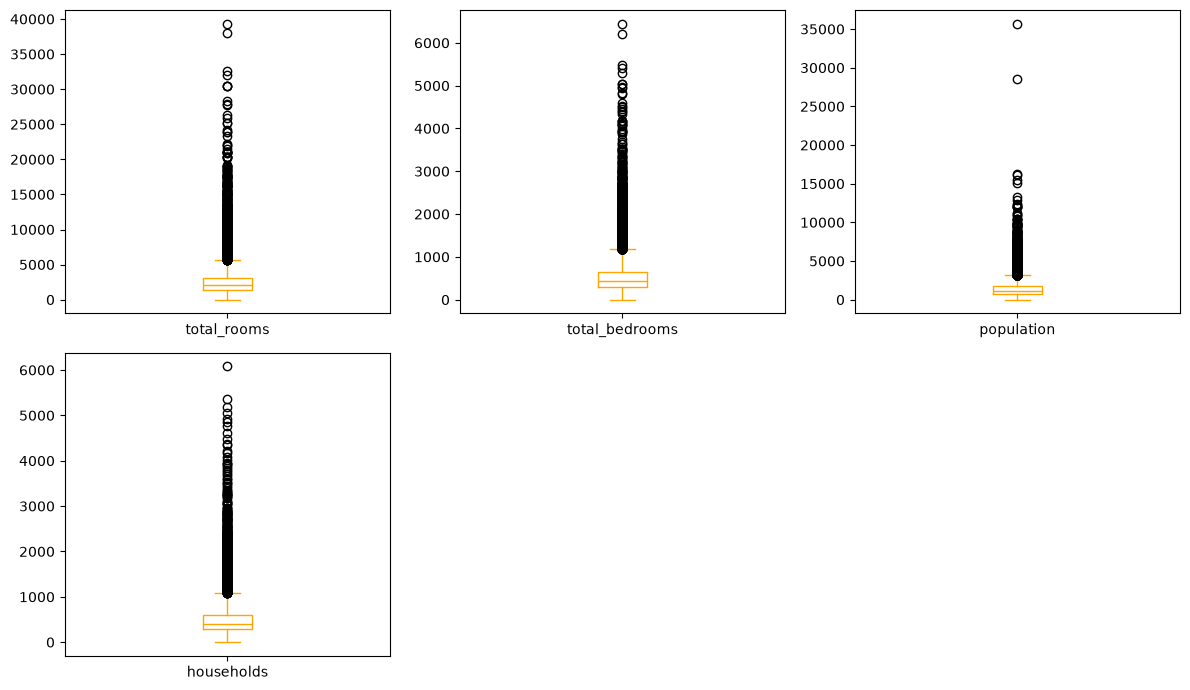

In [44]:
df[columns].plot(
    kind="box",
    subplots=True,
    layout=(2, 3),
    figsize=(12, 7),
    color="orange"
)

plt.tight_layout()
plt.show()

In [20]:
q1 = df['total_bedrooms'].quantile(0.25)
q3 = df['total_bedrooms'].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
print("Q1", q1)
print("Q3", q3)
print("IQR", iqr)
print("Low", low)
print("High", high)


Q1 296.0
Q3 647.0
IQR 351.0
Low -230.5
High 1173.5


In [59]:
outliers = (df['total_bedrooms'] > high).sum()
print("Number of outliers:", outliers)

Number of outliers: 1271


In [62]:
df[df['total_bedrooms'] > high].head(10)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
95,-122.26,37.80,36.0,5329.0,2477.0,3469.0,2323.0,2.0096,130000.0,NEAR BAY
96,-122.26,37.82,31.0,4596.0,1331.0,2048.0,1180.0,2.8345,183800.0,NEAR BAY
98,-122.26,37.82,22.0,3682.0,1270.0,2024.0,1250.0,1.2185,170000.0,NEAR BAY
107,-118.39,34.08,27.0,6605.0,1710.0,2665.0,1520.0,3.8088,500001.0,<1H OCEAN
117,-117.47,34.12,6.0,10565.0,1767.0,5690.0,1555.0,4.1797,141000.0,INLAND
146,-122.51,38.06,24.0,9493.0,1935.0,5162.0,1880.0,3.0742,118800.0,NEAR BAY
149,-118.26,33.85,24.0,9071.0,1335.0,4558.0,1327.0,5.5420,197500.0,<1H OCEAN
158,-116.39,33.69,10.0,11659.0,2007.0,2186.0,1083.0,6.9833,238800.0,INLAND
212,-122.04,37.39,5.0,8745.0,2211.0,3959.0,2019.0,4.7685,280100.0,<1H OCEAN
225,-121.96,38.33,3.0,7985.0,1257.0,3664.0,1215.0,4.9760,158300.0,INLAND


Data Cleaning Documentation

1. Missing Values

Found 207 missing values in total_bedrooms (approximately 1%).

Replaced missing values with the median of 435.

Chose the median because it is less affected by outliers than the mean.

2. Duplicate Records

Checked for duplicate records using df.duplicated().sum().

Found 0 duplicate records.

No records were removed.

3. Invalid Values

Checked numerical columns for negative and zero values.

Investigated potentially invalid values in housing-related columns.

4. Categorical Values

Checked the ocean_proximity column.

Found five expected categories.

No missing or unexpected categories were identified.

5. Data Consistency

Checked whether total bedrooms exceeded total rooms.

Checked whether households exceeded population.

All three consistency checks returned 0.

6. Outlier Investigation

Used box plots and the IQR method to identify potential outliers.

Investigated unusually high values in numerical columns.

Retained outliers because no clear data errors were identified.

7. Capped Values

Found that 6.16% of records have housing_median_age equal to 52.

Found that 4.67% of records have median_house_value equal to 500,001.

Retained these records and documented the potential limitations.

8. Final Validation

Recheck missing values, duplicates, invalid values and data types.

Confirm the dataset is consistent before saving.

Status: Final validation pending.